# Finding Objects in Satellite Images with Faster R-CNN
### GeoAI notebook using **TorchGeo**

**Object detection** means finding *what* is in an image and *where* it is: the model draws a box around each object and gives it a label, like *"airplane, 97 % sure"*.

In this notebook we teach a computer to spot **airplanes, ships, storage tanks, sports fields, bridges, harbors and vehicles** in satellite images. We use **TorchGeo**, a Python library built for AI on satellite and aerial imagery, which handles most of the hard work for us.

**What you'll do**
1. Download and look at a satellite image dataset
2. Split it into **train**, **validation** and **test** sets
3. Learn (in plain words) how Faster R-CNN works
4. Train a Faster R-CNN model
5. Check how good it is on images it has never seen
6. Try it on your own satellite image


## 1 · Setup
This installs TorchGeo. It also brings PyTorch Lightning, which runs the training loop for us. It takes about a minute.

In [1]:
!pip install -q torchgeo

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.7/44.7 kB 2.0 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 45.0/45.0 kB 2.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 812.4/812.4 kB 20.3 MB/s eta 0:00:0000:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 174.8/174.8 kB 6.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 891.2/891.2 kB 32.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 849.3/849.3 kB 37.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 154.8/154.8 kB 7.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 165.6/165.6 kB 9.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 168.8/168.8 kB 7.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6.7/6.7 MB 94.7 MB/s eta 0:00:00:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 803.9/803.9 kB 21.8 MB/s eta 0:00:0000:01


In [2]:
import gc
import torch
import pandas as pd
import matplotlib.pyplot as plt
from collections import Counter

from torchgeo.datasets import VHR10
from torchgeo.datamodules import VHR10DataModule
from torchgeo.tasks import ObjectDetection
from torchvision.models import ResNet50_Weights
from lightning.pytorch import Trainer, seed_everything
from lightning.pytorch.callbacks import ModelCheckpoint
from lightning.pytorch.loggers import CSVLogger

seed_everything(0)
GPU = torch.cuda.is_available()
print("GPU available:", GPU)
if not GPU:
    print("⚠️ No GPU")

Seed set to 0


GPU available: True


## 2 · The dataset: NWPU VHR-10

**NWPU VHR-10** is a classic remote sensing dataset: **650 satellite and aerial images** (mostly from Google Earth, 0.5–2 m per pixel) with about **3,800 labelled objects** in **10 classes**.

TorchGeo downloads it for us (about 77 MB) with a single line.

In [3]:
dataset = VHR10(root="data", download=True)

print("Number of images:", len(dataset))
print("Classes:", dataset.categories[1:])   # class 0 is "background"

NWPU VHR-10 dataset.zip: 100%|██████████| 73.3M/73.3M [00:01<00:00, 57.1MB/s]
annotations.json: 100%|██████████| 1.21M/1.21M [00:00<00:00, 31.9MB/s]


Number of images: 650
Classes: ('airplane', 'ship', 'storage tank', 'baseball diamond', 'tennis court', 'basketball court', 'ground track field', 'harbor', 'bridge', 'vehicle')


### Let's look at some images
Every coloured box is a **label** drawn by a person. These are the "answers" the model learns from.

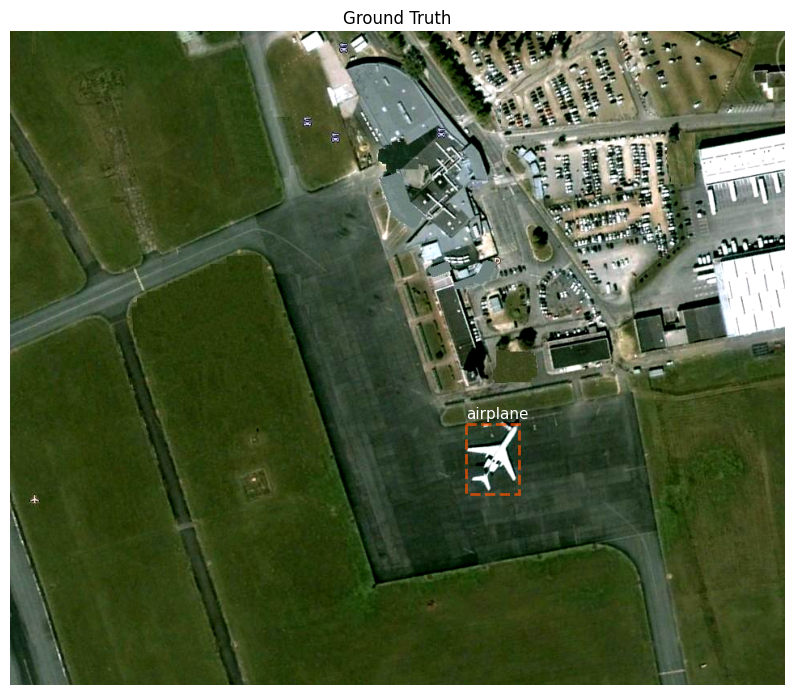

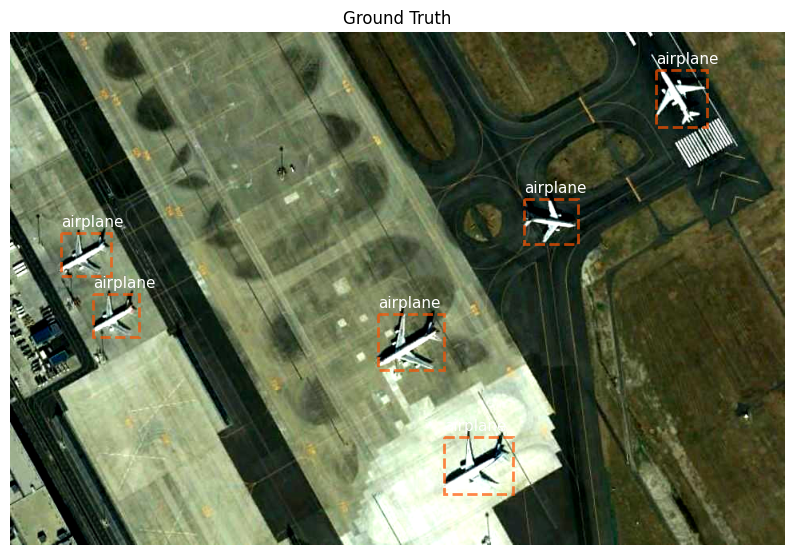

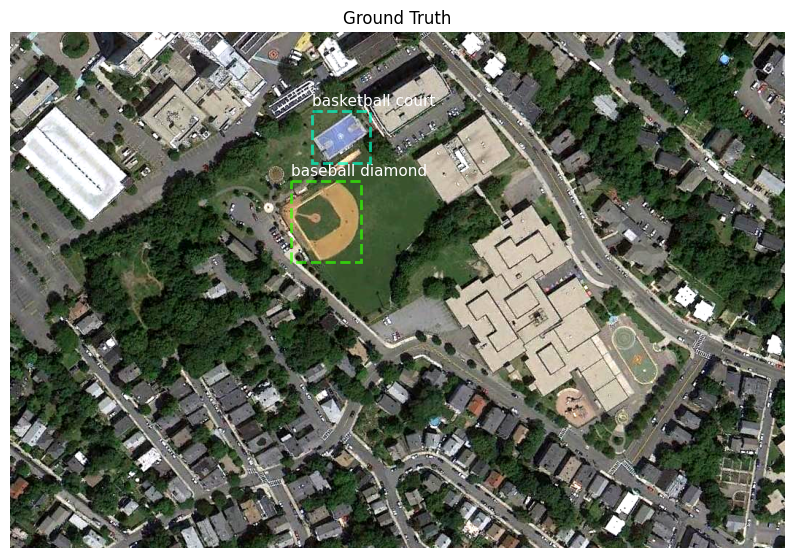

In [4]:
for i in [0, 45, 120]:
    dataset.plot(dataset[i], show_feats="boxes")
    plt.show()

### How many objects of each class?
Some classes are common (airplanes, storage tanks) and some are rare (bridges, basketball courts). Rare classes are usually harder for the model, because it sees fewer examples.

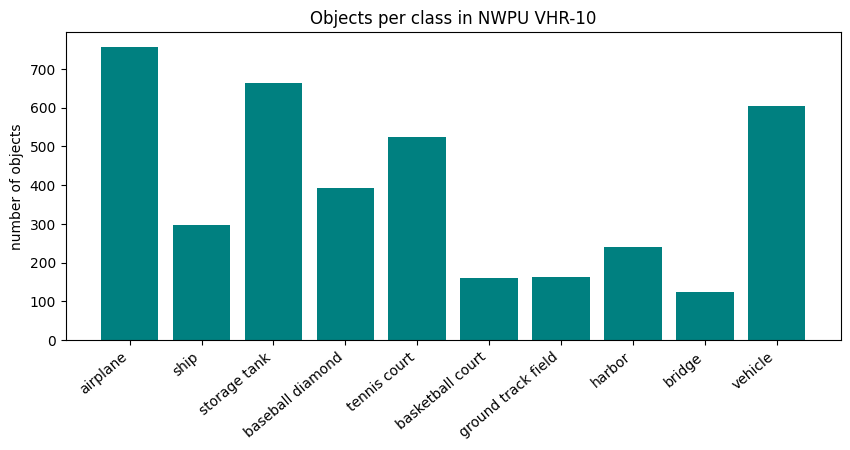

In [5]:
counts = Counter(label for labels in dataset.labels.values() for label in labels)
names = [dataset.categories[c] for c in sorted(counts)]
values = [counts[c] for c in sorted(counts)]

plt.figure(figsize=(10, 4))
plt.bar(names, values, color="teal")
plt.xticks(rotation=40, ha="right")
plt.ylabel("number of objects")
plt.title("Objects per class in NWPU VHR-10")
plt.show()

### Free up memory
When TorchGeo loads VHR-10 it keeps the outline of every object in memory, about 2–3 GB. The training step below loads its own copy, so we delete the one we used for exploring. Colab has only ~12 GB of RAM, and two copies plus training can run out.

In [6]:
del dataset
gc.collect()
print("Exploration copy removed")

Exploration copy removed


## 3 · Train, validation and test sets

We split the images into three groups.


The test images must stay hidden until the end. If we peeked at them while training, the final score would be too optimistic.

TorchGeo's `VHR10DataModule` does the split for us, always in the same way (fixed random seed). It also **resizes** every image to 512 × 512 pixels and adds simple **flips** during training, so the model sees more variety.

In [7]:
datamodule = VHR10DataModule(
    root="data",
    batch_size=8,          # images processed together in one step
    patch_size=512,        # every image is resized to 512 x 512
    val_split_pct=0.2,     # 20 % validation
    test_split_pct=0.2,    # 20 % test
    num_workers=0,         # load images in the main process: avoids extra copies of the data in RAM
)
datamodule.setup("fit")

print("train images:     ", len(datamodule.train_dataset))
print("validation images:", len(datamodule.val_dataset))
print("test images:      ", len(datamodule.test_dataset))

train images:      390
validation images: 130
test images:       130


## 4 · How does Faster R-CNN work?

Faster R-CNN finds objects in **two stages**, a bit like how you might search a satellite photo yourself:

```
                 ┌──────────────────────────┐
 satellite  ──►  │ 1. BACKBONE (ResNet-50)  │  "looks" at the image and turns it
 image           │    + feature pyramid     │  into feature maps (edges, shapes,
                 └────────────┬─────────────┘  textures) at several zoom levels
                              ▼
                 ┌──────────────────────────┐
                 │ 2. REGION PROPOSAL       │  "Where might something be?"
                 │    NETWORK (RPN)         │  suggests ~1000 candidate boxes
                 └────────────┬─────────────┘
                              ▼
                 ┌──────────────────────────┐
                 │ 3. DETECTION HEAD        │  "What is in each box?"
                 │                          │  → label + confidence + tighter box
                 └────────────┬─────────────┘
                              ▼
                 airplane 0.97 · ship 0.88 · vehicle 0.71 …
```

- **Stage 1, "Where?":** the *Region Proposal Network* scans the whole image and proposes boxes that might contain *something*. It doesn't yet know what.
- **Stage 2, "What?":** the *detection head* examines each proposed box, decides the class (or "background" = nothing), gives a **confidence score**, and adjusts the box to fit better.
- **Removing duplicates:** a step called *non-maximum suppression* removes overlapping boxes around the same object.


## 5 · Create the model
TorchGeo builds the whole Faster R-CNN with one line. We tell it:
- `model="faster-rcnn"`: the detector we want
- `backbone="resnet50"` with ImageNet weights
- `num_classes=11`: our 10 object classes plus "background"

In [8]:
class ObjectDetectionWithLosses(ObjectDetection):
    """TorchGeo's ObjectDetection, plus the average train and validation loss per epoch."""

    def training_step(self, batch, batch_idx, dataloader_idx=0):
        loss = super().training_step(batch, batch_idx, dataloader_idx)
        self.log("train_loss", loss, on_step=False, on_epoch=True, batch_size=len(batch["image"]))
        return loss

    def validation_step(self, batch, batch_idx, dataloader_idx=0):
        targets = [{"boxes": b, "labels": l} for b, l in zip(batch["bbox_xyxy"], batch["label"])]
        self.model.train()                      # losses are only computed in training mode
        with torch.no_grad():                   # ...but no learning happens here
            losses = self.model(batch["image"], targets)
        self.model.eval()
        self.log("val_loss", sum(losses.values()), on_step=False, on_epoch=True,
                 batch_size=len(batch["image"]))
        super().validation_step(batch, batch_idx, dataloader_idx)   # computes val_map as before


task = ObjectDetectionWithLosses(
    model="faster-rcnn",
    backbone="resnet50",
    weights=ResNet50_Weights.IMAGENET1K_V1,
    num_classes=11,
    lr=1e-4,               # learning rate: how big each learning step is
)
print(f"Model ready, with {sum(p.numel() for p in task.parameters()) / 1e6:.0f} million parameters")

Downloading: "https://download.pytorch.org/models/resnet50-0676ba61.pth" to /root/.cache/torch/hub/checkpoints/resnet50-0676ba61.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 163MB/s]


Model ready, with 41 million parameters


## 6 · Train the model

**mAP** (mean Average Precision) is the standard score for object detection. It goes from 0 (useless) to 1 (perfect) and rewards finding every object with a well-placed box and the right label.


In [9]:
EPOCHS = 25

checkpoint = ModelCheckpoint(monitor="val_map", mode="max", filename="best")
trainer = Trainer(
    max_epochs=EPOCHS,
    accelerator="gpu" if GPU else "cpu",
    precision="16-mixed" if GPU else "32-true",   # faster training on GPU
    callbacks=[checkpoint],
    logger=CSVLogger("logs"),
    log_every_n_steps=10,
)
trainer.fit(task, datamodule=datamodule)
print("Best checkpoint:", checkpoint.best_model_path)

Trainer will use only 1 of 2 GPUs because it is running inside an interactive / notebook environment. You may try to set `Trainer(devices=2)` but please note that multi-GPU inside interactive / notebook environments is considered experimental and unstable. Your mileage may vary.
Using 16bit Automatic Mixed Precision (AMP)
GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0,1]
/usr/local/lib/python3.13/dist-packages/lightning/pytorch/utilities/model_summary/model_summary.py:242: Precision 16-mixed is not supported by the model summary.  Estimated model size in MB will not be accurate. Using 32 bits instead.


┏━━━┳━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━┳━━━━━━━━┳━━━━━━━┳━━━━━━━┓
┃   ┃ Name         ┃ Type             ┃ Params ┃ Mode  ┃ FLOPs ┃
┡━━━╇━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━╇━━━━━━━━╇━━━━━━━╇━━━━━━━┩
│ 0 │ model        │ FasterRCNN       │ 41.3 M │ train │     0 │
│ 1 │ val_metrics  │ MetricCollection │      0 │ train │     0 │
│ 2 │ test_metrics │ MetricCollection │      0 │ train │     0 │
└───┴──────────────┴──────────────────┴────────┴───────┴───────┘

Trainable params: 41.1 M                                                                                           
Non-trainable params: 212 K                                                                                        
Total params: 41.3 M                                                                                               
Total estimated model params size (MB): 165.381                                                                    
Modules in train mode: 193                                                                                         
Modules in eval mode: 0                                                                                            
Total FLOPs: 0

Output()

/usr/local/lib/python3.13/dist-packages/lightning/pytorch/utilities/_pytree.py:21: `isinstance(treespec, LeafSpec)`
is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.

/usr/local/lib/python3.13/dist-packages/lightning/pytorch/trainer/connectors/data_connector.py:434: The 
'val_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the 
`num_workers` argument` to `num_workers=3` in the `DataLoader` to improve performance.

/usr/local/lib/python3.13/dist-packages/lightning/pytorch/trainer/connectors/data_connector.py:434: The 
'train_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the 
`num_workers` argument` to `num_workers=3` in the `DataLoader` to improve performance.

`Trainer.fit` stopped: `max_epochs=25` reached.


Best checkpoint: logs/lightning_logs/version_0/checkpoints/best.ckpt


### Did the model improve?
The validation score per epoch. It should rise quickly at first, then flatten out.

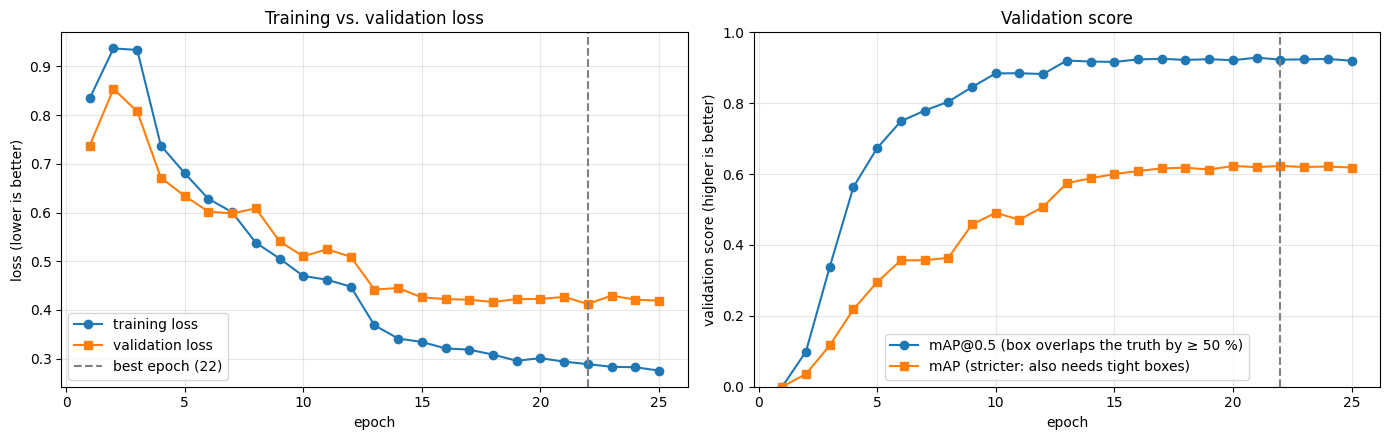

In [10]:
log = pd.read_csv(f"{trainer.logger.log_dir}/metrics.csv")
train = log.dropna(subset=["train_loss"]).groupby("epoch").last()
val = log.dropna(subset=["val_map"]).groupby("epoch").last()
best_epoch = val["val_map"].idxmax() + 1

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4.5))

ax1.plot(train.index + 1, train["train_loss"], "o-", label="training loss")
ax1.plot(val.index + 1, val["val_loss"], "s-", label="validation loss")
ax1.axvline(best_epoch, color="gray", ls="--", label=f"best epoch ({best_epoch})")
ax1.set_xlabel("epoch"); ax1.set_ylabel("loss (lower is better)")
ax1.set_title("Training vs. validation loss"); ax1.legend(); ax1.grid(alpha=0.3)

ax2.plot(val.index + 1, val["val_map_50"], "o-", label="mAP@0.5 (box overlaps the truth by ≥ 50 %)")
ax2.plot(val.index + 1, val["val_map"], "s-", label="mAP (stricter: also needs tight boxes)")
ax2.axvline(best_epoch, color="gray", ls="--")
ax2.set_xlabel("epoch"); ax2.set_ylabel("validation score (higher is better)"); ax2.set_ylim(0, 1)
ax2.set_title("Validation score"); ax2.legend(); ax2.grid(alpha=0.3)
plt.tight_layout(); plt.show()

##  The test set
Now we load the **best** model (chosen on validation) and evaluate it **once** on the test images it has never seen.

In [11]:
best_task = ObjectDetectionWithLosses.load_from_checkpoint(checkpoint.best_model_path)
results = trainer.test(best_task, datamodule=datamodule)[0]

print("\n📊 Test results")
print(f"  mAP@0.5     : {results['test_map_50']:.2f}   ← the most common headline number")
print(f"  mAP@0.75    : {results['test_map_75']:.2f}   ← needs tighter boxes")
print(f"  mAP         : {results['test_map']:.2f}   ← average over strictness levels")

LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0,1]


Output()

/usr/local/lib/python3.13/dist-packages/lightning/pytorch/utilities/_pytree.py:21: `isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.
/usr/local/lib/python3.13/dist-packages/lightning/pytorch/trainer/connectors/data_connector.py:434: The 'test_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=3` in the `DataLoader` to improve performance.


┏━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃        Test metric        ┃       DataLoader 0        ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━┩
│         test_map          │    0.5753594040870667     │
│        test_map_50        │    0.8977248072624207     │
│        test_map_75        │    0.6319816708564758     │
│      test_map_large       │    0.6462910175323486     │
│      test_map_medium      │    0.5825242400169373     │
│    test_map_per_class     │           -1.0            │
│      test_map_small       │    0.3586934804916382     │
│        test_mar_1         │    0.29629209637641907    │
│        test_mar_10        │    0.5921306610107422     │
│       test_mar_100        │    0.6248120069503784     │
│  test_mar_100_per_class   │           -1.0            │
│      test_mar_large       │    0.6714529395103455     │
│      test_mar_medium      │    0.6319708824157715     │
│      test_mar_small       │    0.3928922116756439     │
└───────────────────────────┴───────────────────────────┘


📊 Test results
  mAP@0.5     : 0.90   ← the most common headline number
  mAP@0.75    : 0.63   ← needs tighter boxes
  mAP         : 0.58   ← average over strictness levels


 a test **mAP@0.5 of 0.80** would mean that, roughly, when the model draws a box, it is usually on a real object with the right label, and it finds most of the objects. If the test score is close to the best validation score, the model **generalises** well to new images.

In [12]:
from torchvision.ops import nms

def clean(pred, min_score=0.5, max_overlap=0.3):
    """Keep confident boxes, then remove overlapping duplicates, even across classes."""
    keep = pred["scores"] >= min_score
    pred = {k: v[keep] for k, v in pred.items()}
    keep = nms(pred["boxes"], pred["scores"], max_overlap)   # keeps the most confident box
    return {k: v[keep] for k, v in pred.items()}

##  See the model in action
Left: the human labels. Right: what the model found (boxes with confidence ≥ 0.5). These are **test** images, which the model never saw during training.

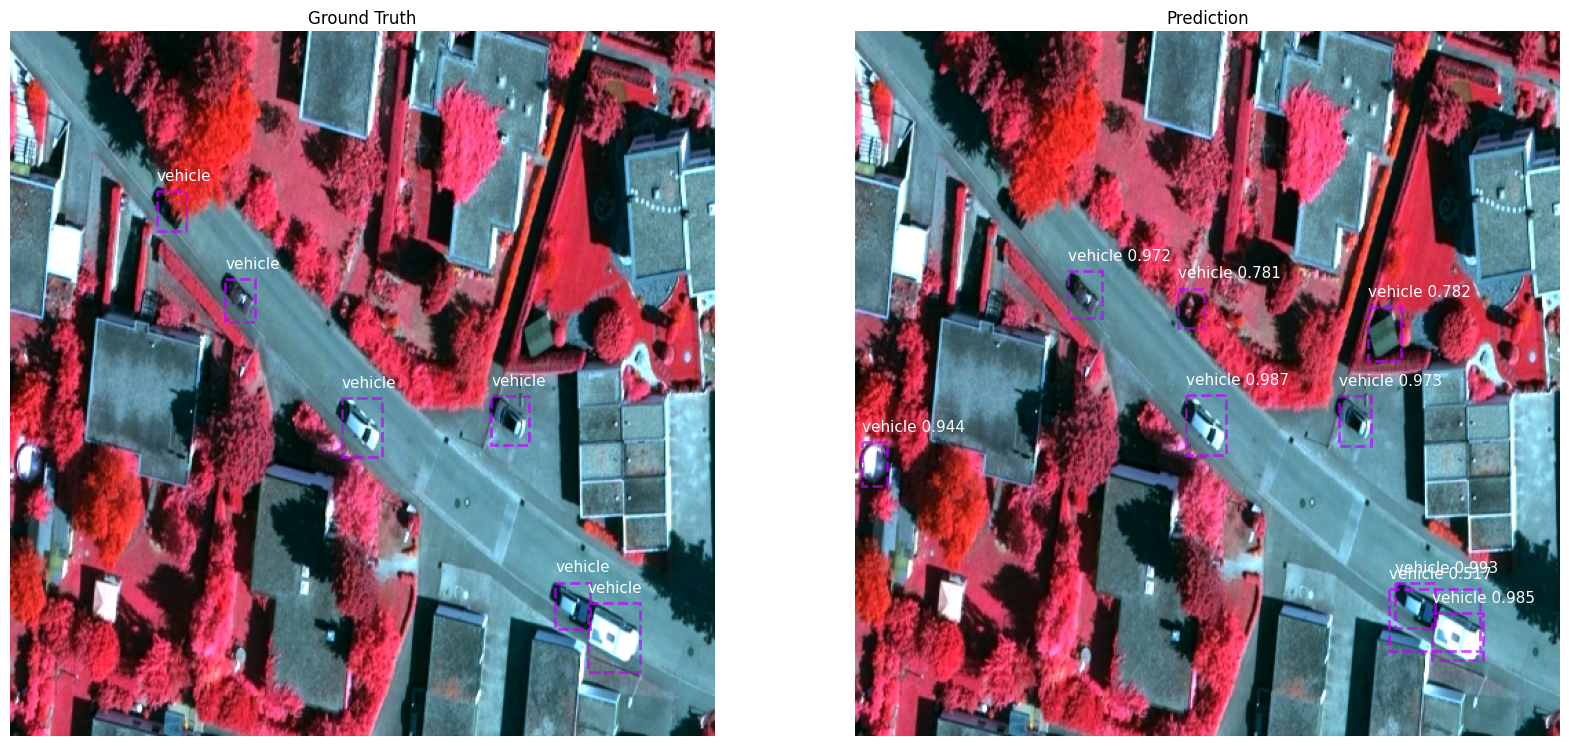

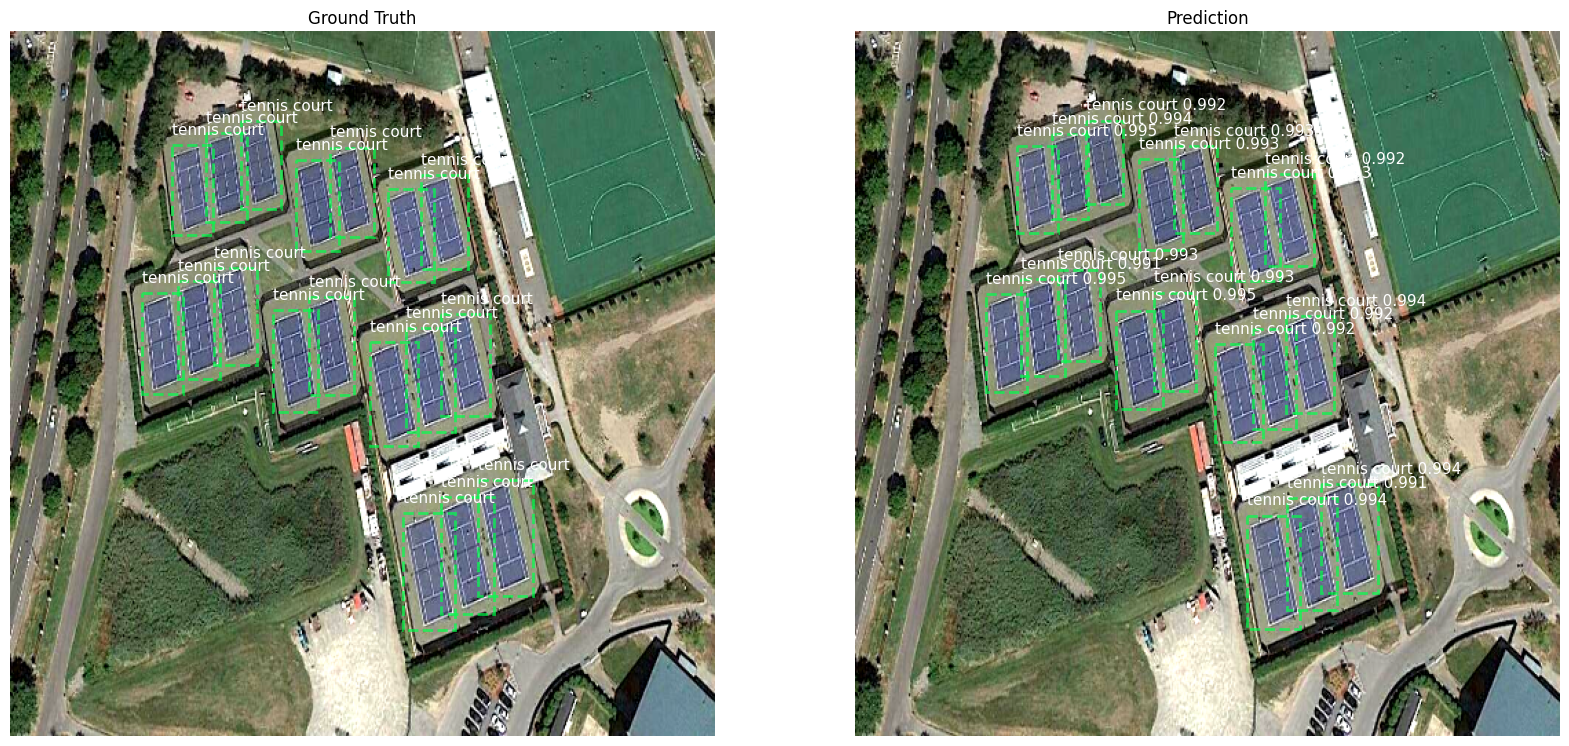

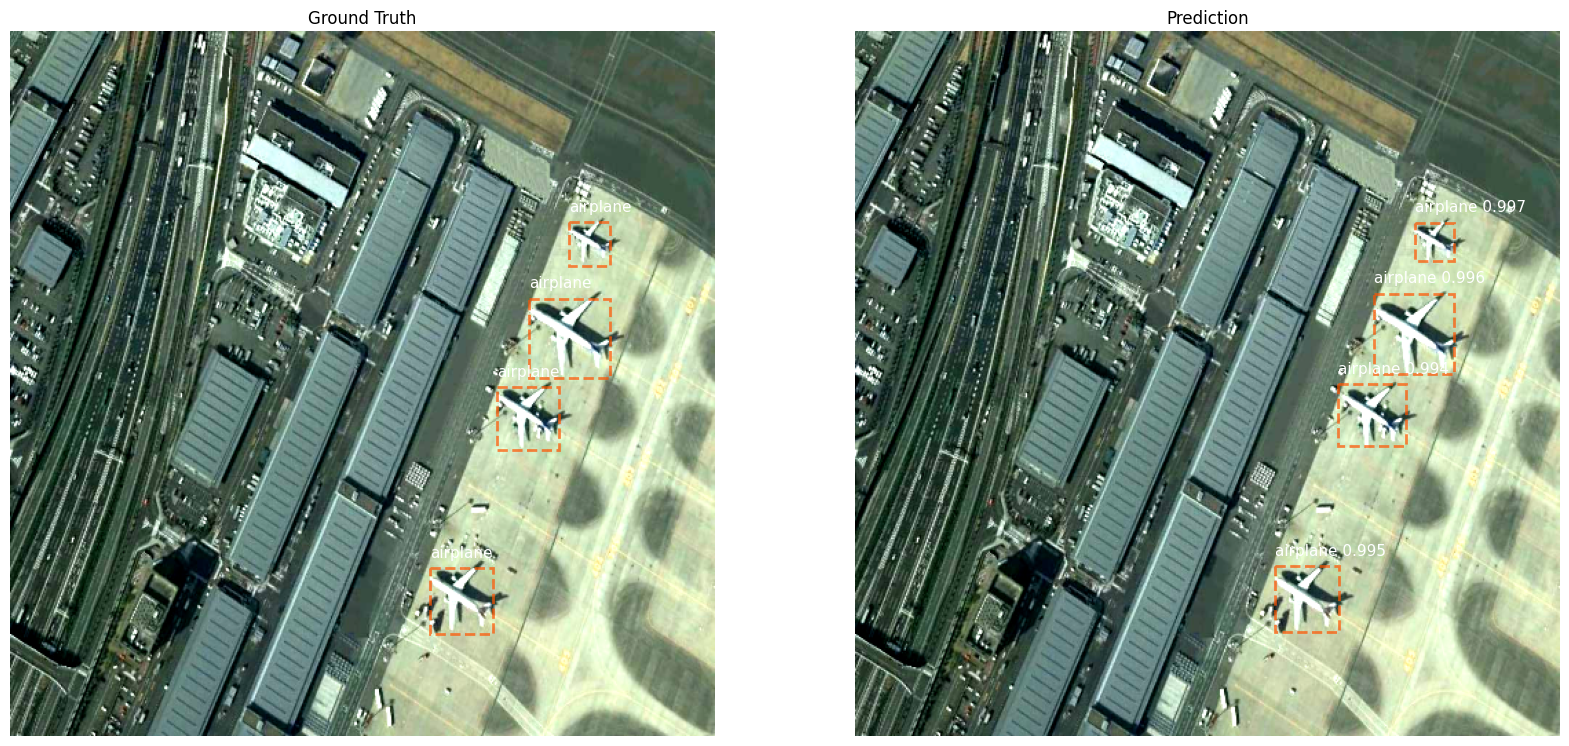

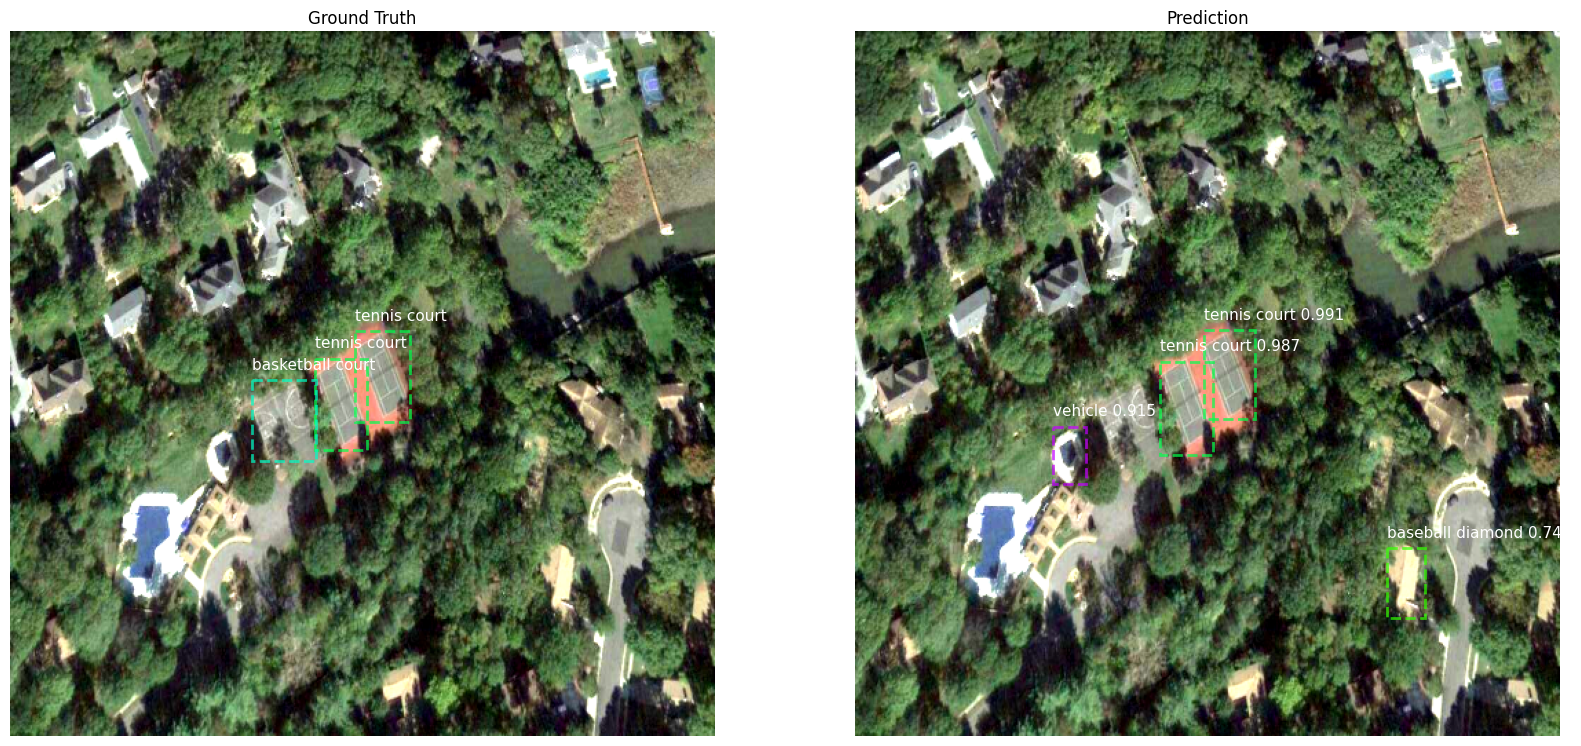

In [13]:
model = best_task.model.eval()
device = "cuda" if GPU else "cpu"
model.to(device)
datamodule.setup("test")
test_set = datamodule.test_dataset

def show_prediction(i):
    sample = test_set[i]
    image = sample["image"] / 255.0               # pixel values 0–255 → 0–1, as in training
    with torch.no_grad():
        pred = clean(model(image.unsqueeze(0).to(device))[0])
    sample["prediction_bbox_xyxy"] = pred["boxes"].cpu()
    sample["prediction_label"] = pred["labels"].cpu()
    sample["prediction_score"] = pred["scores"].cpu()
    test_set.dataset.plot(sample, show_feats="boxes")
    plt.show()

for i in [0, 1, 2, 3]:
    show_prediction(i)

### Which objects are easy, and which are hard?
The score for each class separately, on the test set.

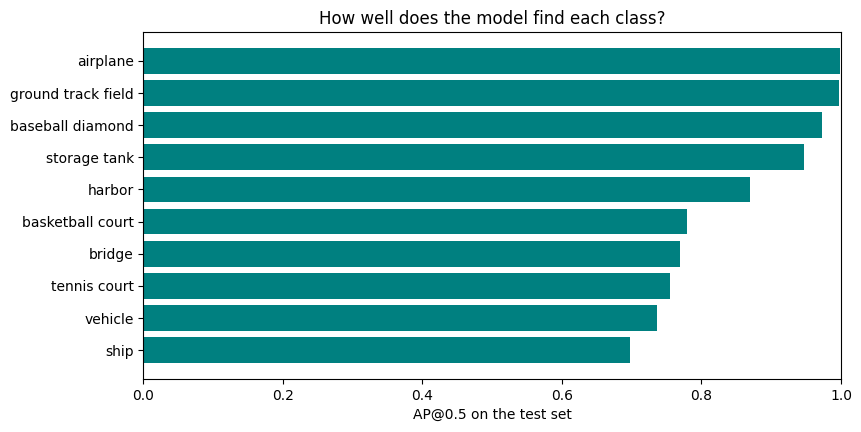

In [14]:
from torchmetrics.detection import MeanAveragePrecision

metric = MeanAveragePrecision(iou_thresholds=[0.5], class_metrics=True)
with torch.no_grad():
    for i in range(len(test_set)):
        sample = test_set[i]
        pred = model((sample["image"] / 255.0).unsqueeze(0).to(device))[0]
        metric.update([{k: v.cpu() for k, v in pred.items()}],
                      [{"boxes": sample["bbox_xyxy"], "labels": sample["label"]}])
scores = metric.compute()

per_class = {VHR10.categories[int(c)]: float(ap)
             for c, ap in zip(scores["classes"], scores["map_per_class"])}
per_class = dict(sorted(per_class.items(), key=lambda kv: kv[1]))

plt.figure(figsize=(9, 4.5))
plt.barh(list(per_class), list(per_class.values()), color="teal")
plt.xlim(0, 1); plt.xlabel("AP@0.5 on the test set")
plt.title("How well does the model find each class?")
plt.show()



### 🔗 Learn more
- TorchGeo documentation and tutorials: https://torchgeo.readthedocs.io
- NWPU VHR-10 paper: Cheng et al., *ISPRS J. Photogramm. Remote Sens.*, 2014, doi:10.1016/j.isprsjprs.2014.10.002
- Faster R-CNN paper: Ren et al., *NeurIPS* 2015